# Khmer Emotion Classification — Final Balanced Benchmark

**Course:** ITM 454 002  
**Task:** Seven-class Khmer emotion classification  
**Comparison:** CLAWS word TF–IDF + linear SVM vs. XLM-RoBERTa  
**Primary metric:** macro F1 on a held-out test set

## Final experimental policy

1. Scan and clean the entire corpus.
2. Remove verified generator identifiers and exact duplicates.
3. Cluster near-duplicate templates and keep one deterministic representative.
4. Keep all cleaned near-unique examples from the six smaller classes and cap only the oversized `stress` class at the largest non-stress class size.
5. Assign every retained unique record to train (80%), validation (10%), or test (10%).
6. Train both models on the same split.
7. Use validation data for model selection and evaluate the test set once.
8. Report limitations honestly; this is a synthetic/template-heavy benchmark, not real-world accuracy.

## 1. Environment

Run these commands once in the active notebook kernel, then restart the kernel:

```python
%pip install -q pandas pyarrow numpy scipy scikit-learn matplotlib seaborn joblib tqdm datasketch claws-tokenizer
%pip install -q "torch>=2.2" "transformers>=4.46,<5" "datasets>=3,<5" "accelerate>=1,<2" sentencepiece
```

After installation, restart the kernel and choose **Run All**. The notebook is ordered from raw data to final artifacts; no cell needs to be run manually out of order.

Expensive completed stages are stored under `artifacts_professional/balanced-near-v2/` and validated by data/configuration fingerprints. A normal rerun reuses exact-deduplication, near-duplicate, CLAWS-token, and XLM-R checkpoint work. Leave every `force_*` configuration option set to `False` for the final rerun.

CLAWS is used only for the statistical word model. XLM-R receives normalized Khmer text through its own tokenizer.

In [1]:
# %pip install -q pandas pyarrow numpy scipy scikit-learn matplotlib seaborn joblib tqdm datasketch claws-tokenizer
# %pip install -q "torch>=2.2" "transformers>=4.46,<5" "datasets>=3,<5" "accelerate>=1,<2" sentencepiece

In [2]:
from pathlib import Path
from collections import Counter
from dataclasses import dataclass, asdict
from functools import lru_cache
import hashlib
import importlib.metadata as metadata
import json
import math
import platform
import re
import sqlite3
import time
import unicodedata
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import seaborn as sns
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, f1_score,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.svm import LinearSVC
from tqdm.auto import tqdm

@dataclass(frozen=True)
class ExperimentConfig:
    seed: int = 42
    pipeline_version: str = "balanced-near-v2"
    near_duplicate_threshold: float = 0.65
    shingle_size: int = 5
    minhash_permutations: int = 128
    svm_c_values: tuple = (0.1, 1.0, 10.0)
    force_rebuild_dedup: bool = False
    force_rebuild_near_duplicates: bool = False
    force_retokenize: bool = False
    run_xlmr: bool = True
    xlmr_model: str = "FacebookAI/xlm-roberta-base"
    xlmr_epochs: int = 3
    xlmr_batch_size: int = 1
    xlmr_gradient_accumulation: int = 16
    max_length: int = 144
    token_checkpoint_every: int = 250
    bootstrap_repeats: int = 2_000

CFG = ExperimentConfig()
ROOT = Path.cwd()
FILES = [ROOT / f"train-{i:05d}-of-00003.parquet" for i in range(3)]
if not all(path.is_file() for path in FILES):
    missing = [str(path) for path in FILES if not path.is_file()]
    raise FileNotFoundError(f"Missing Parquet shards: {missing}")

LABELS = ["angry", "fear", "happy", "lonely", "neutral", "sad", "stress"]
label2id = {label: i for i, label in enumerate(LABELS)}
id2label = {i: label for label, i in label2id.items()}
BOOTSTRAP_REPEATS = CFG.bootstrap_repeats

OUT = ROOT / "artifacts_professional" / CFG.pipeline_version
OUT.mkdir(parents=True, exist_ok=True)

packages = [
    "pandas", "pyarrow", "numpy", "scikit-learn", "claws-tokenizer",
    "datasketch", "torch", "transformers", "datasets", "accelerate",
]
versions = {}
for package in packages:
    try:
        versions[package] = metadata.version(package)
    except metadata.PackageNotFoundError:
        versions[package] = "not installed"

print("Python:", platform.python_version())
print("Output:", OUT)
print("Configuration:", json.dumps(asdict(CFG), indent=2))
print("Package versions:", versions)

Python: 3.11.18
Output: /Users/thisisnotleng/Desktop/AUPP/NLP/Pilot Test Final/artifacts_professional/balanced-near-v2
Configuration: {
  "seed": 42,
  "pipeline_version": "balanced-near-v2",
  "near_duplicate_threshold": 0.65,
  "shingle_size": 5,
  "minhash_permutations": 128,
  "svm_c_values": [
    0.1,
    1.0,
    10.0
  ],
  "force_rebuild_dedup": false,
  "force_rebuild_near_duplicates": false,
  "force_retokenize": false,
  "run_xlmr": true,
  "xlmr_model": "FacebookAI/xlm-roberta-base",
  "xlmr_epochs": 3,
  "xlmr_batch_size": 8,
  "xlmr_gradient_accumulation": 2,
  "max_length": 192,
  "token_checkpoint_every": 250,
  "bootstrap_repeats": 2000
}
Package versions: {'pandas': '3.1.1', 'pyarrow': '26.0.1', 'numpy': '2.4.6', 'scikit-learn': '1.9.1', 'claws-tokenizer': '0.1.2', 'datasketch': '2.0.0', 'torch': '2.15.0', 'transformers': '4.57.6', 'datasets': '4.8.5', 'accelerate': '1.15.0'}


## 2. Input fingerprint and cache identity

A cache must be invalidated when either the input data **or the cleaning policy** changes. File modification time alone is not sufficient. The manifest therefore records SHA-256 hashes, schema, configuration, and the explicit pipeline version.

In [3]:
def sha256_file(path, chunk_size=8 * 1024 * 1024):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        while chunk := handle.read(chunk_size):
            digest.update(chunk)
    return digest.hexdigest()

manifest = {
    "pipeline_version": CFG.pipeline_version,
    "labels": LABELS,
    "files": [
        {
            "file": path.name,
            "rows": pq.ParquetFile(path).metadata.num_rows,
            "bytes": path.stat().st_size,
            "sha256": sha256_file(path),
            "schema": str(pq.ParquetFile(path).schema_arrow),
        }
        for path in FILES
    ],
}
manifest_fingerprint = hashlib.sha256(
    json.dumps(manifest, sort_keys=True).encode("utf-8")
).hexdigest()

display(pd.DataFrame(manifest["files"])[["file", "rows", "bytes", "sha256"]])
print("Input/pipeline fingerprint:", manifest_fingerprint)
(OUT / "input_manifest.json").write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8"
)

,file,rows,bytes,sha256
0,train-00000-of-00003.parquet,1395030,47309910,c0c1b968e27608bf025c64add0f31b682e0df379516ed6...
1,train-00001-of-00003.parquet,1395030,32843138,a09d086a9a83ac9e8ac3c0520e6e029b330f5e38ec7170...
2,train-00002-of-00003.parquet,1395030,80645559,fc4e1ba829ea5870338e4dddb5198022f6d44e45661b2d...


Input/pipeline fingerprint: 35c830b7eabc10b634ec8f420b8f471570bb511f285765d3405abb35df1a694a


1269

## 3. Cleaning policy and exact deduplication

The pipeline preserves raw examples for auditing but models only cleaned text.

Cleaning steps:

1. Unicode NFC normalization.
2. Explicit invisible/control separators converted to spaces.
3. Whitespace collapsed.
4. Verified dataset generator suffixes removed:
   - bare counters such as `(1)`;
   - `(ករណីសិក្សាទី N)`;
   - `(ករណីទី N)`;
   - `(ការគិតអប់រំចិត្តទី N)`.
5. A whitespace-insensitive exact-deduplication key is created.
6. Exact texts with conflicting labels are excluded.

In [4]:
SPACE_RE = re.compile(r"\s+")
INVISIBLE_SEPARATORS_RE = re.compile(r"[\u200b\u200c\u200d\ufeff]")
KHMER_RE = re.compile(r"[\u1780-\u17FF]")
BARE_COUNTER_RE = re.compile(
    r"[\s\u200b\u200c\u200d\ufeff]*\(([0-9០-៩]+)\)"
    r"[\s\u200b\u200c\u200d\ufeff]*$"
)
GENERATOR_MARKER_RE = re.compile(
    r"[\s\u200b\u200c\u200d\ufeff]*"
    r"\((?:ការគិតអប់រំចិត្តទី|ករណីសិក្សាទី|ករណីទី)\s*[0-9០-៩]+\)"
    r"[\s\u200b\u200c\u200d\ufeff]*$"
)

@lru_cache(maxsize=200_000)
def normalize_base(value):
    value = unicodedata.normalize("NFC", value)
    value = INVISIBLE_SEPARATORS_RE.sub(" ", value)
    value = "".join(" " if unicodedata.category(ch) == "Cc" else ch for ch in value)
    return SPACE_RE.sub(" ", value).strip()

def remove_generated_suffix(value):
    marker = GENERATOR_MARKER_RE.search(value)
    if marker:
        return GENERATOR_MARKER_RE.sub("", value).strip(), marker.group(0).strip(), "generator_marker"
    counter = BARE_COUNTER_RE.search(value)
    if counter:
        return BARE_COUNTER_RE.sub("", value).strip(), counter.group(0).strip(), "bare_counter"
    return value, None, None

def canonical_key(value):
    return SPACE_RE.sub("", value)

def prepare_text(raw_text):
    base = normalize_base(raw_text)
    model_text, removed_suffix, removal_rule = remove_generated_suffix(base)
    return {
        "base_text": base,
        "model_text": model_text,
        "pre_suffix_key": canonical_key(base),
        "dedup_key": canonical_key(model_text),
        "removed_suffix": removed_suffix,
        "removal_rule": removal_rule,
    }

examples = [
    "ខ្ញុំសប្បាយចិត្តណាស់។ (1)",
    "ខ្ញុំមានអារម្មណ៍សោកសៅ។ (ករណីសិក្សាទី 10)",
    "ខ្ញុំមានអារម្មណ៍ខឹង។ (ការគិតអប់រំចិត្តទី 66972)",
]
display(pd.DataFrame([{"raw": text, **prepare_text(text)} for text in examples]))

,raw,base_text,model_text,pre_suffix_key,dedup_key,removed_suffix,removal_rule
0,ខ្ញុំសប្បាយចិត្តណាស់។ (1),ខ្ញុំសប្បាយចិត្តណាស់។ (1),ខ្ញុំសប្បាយចិត្តណាស់។,ខ្ញុំសប្បាយចិត្តណាស់។(1),ខ្ញុំសប្បាយចិត្តណាស់។,(1),bare_counter
1,ខ្ញុំមានអារម្មណ៍សោកសៅ។ (ករណីសិក្សាទី 10),ខ្ញុំមានអារម្មណ៍សោកសៅ។ (ករណីសិក្សាទី 10),ខ្ញុំមានអារម្មណ៍សោកសៅ។,ខ្ញុំមានអារម្មណ៍សោកសៅ។(ករណីសិក្សាទី10),ខ្ញុំមានអារម្មណ៍សោកសៅ។,(ករណីសិក្សាទី 10),generator_marker
2,ខ្ញុំមានអារម្មណ៍ខឹង។ (ការគិតអប់រំចិត្តទី 66972),ខ្ញុំមានអារម្មណ៍ខឹង។ (ការគិតអប់រំចិត្តទី 66972),ខ្ញុំមានអារម្មណ៍ខឹង។,ខ្ញុំមានអារម្មណ៍ខឹង។(ការគិតអប់រំចិត្តទី66972),ខ្ញុំមានអារម្មណ៍ខឹង។,(ការគិតអប់រំចិត្តទី 66972),generator_marker


### Build or reuse the audited deduplication database

This stage scans all shards in bounded batches. It reports missing/invalid rows, unique keys before suffix removal, unique keys after suffix removal, duplicate excess, label conflicts, and per-label unique counts.

The validated cache is reused automatically. Set `CFG.force_rebuild_dedup=True` only when intentionally rebuilding this stage.

In [5]:
DB_PATH = OUT / "deduplicated.sqlite"
AUDIT_PATH = OUT / "data_audit.json"
CACHE_META_PATH = OUT / "dedup_cache_meta.json"
expected_cache_meta = {
    "manifest_fingerprint": manifest_fingerprint,
    "pipeline_version": CFG.pipeline_version,
}
cache_valid = (
    DB_PATH.exists()
    and AUDIT_PATH.exists()
    and CACHE_META_PATH.exists()
    and json.loads(CACHE_META_PATH.read_text(encoding="utf-8")) == expected_cache_meta
)

if CFG.force_rebuild_dedup or not cache_valid:
    for suffix in ("", "-wal", "-shm"):
        candidate = Path(str(DB_PATH) + suffix)
        if candidate.exists():
            candidate.unlink()

    db = sqlite3.connect(DB_PATH)
    db.execute("PRAGMA journal_mode=WAL")
    db.execute("PRAGMA synchronous=NORMAL")
    db.execute("""
        CREATE TABLE texts (
            dedup_key TEXT PRIMARY KEY,
            model_text TEXT NOT NULL,
            raw_example TEXT NOT NULL,
            label_mask INTEGER NOT NULL,
            copies INTEGER NOT NULL,
            suffix_copies INTEGER NOT NULL,
            first_id TEXT NOT NULL,
            first_file TEXT NOT NULL
        )
    """)
    db.execute("CREATE TABLE pre_suffix_keys (key TEXT PRIMARY KEY)")
    upsert = """
        INSERT INTO texts VALUES (?, ?, ?, ?, ?, ?, ?, ?)
        ON CONFLICT(dedup_key) DO UPDATE SET
            label_mask = texts.label_mask | excluded.label_mask,
            copies = texts.copies + excluded.copies,
            suffix_copies = texts.suffix_copies + excluded.suffix_copies
    """

    rejected = Counter()
    raw_labels = Counter()
    raw_rows = 0
    rows_with_generated_suffix = 0
    generated_suffix_examples = []
    started = time.perf_counter()

    for path in FILES:
        parquet_file = pq.ParquetFile(path)
        progress = tqdm(
            parquet_file.iter_batches(batch_size=50_000, columns=["id", "text", "label"]),
            total=math.ceil(parquet_file.metadata.num_rows / 50_000),
            desc=f"Audit {path.name}",
        )
        for batch in progress:
            rows = batch.to_pydict()
            grouped = {}
            pre_suffix_batch = set()
            for ident, raw_text, label in zip(rows["id"], rows["text"], rows["label"]):
                raw_rows += 1
                label = label.strip().lower() if isinstance(label, str) else "<missing>"
                raw_labels[label] += 1

                if ident is None:
                    rejected["missing_id"] += 1
                    continue
                if not isinstance(raw_text, str):
                    rejected["missing_or_nonstring_text"] += 1
                    continue
                if label not in label2id:
                    rejected["unexpected_label"] += 1
                    continue

                prepared = prepare_text(raw_text)
                model_text = prepared["model_text"]
                if not model_text:
                    rejected["empty_after_cleaning"] += 1
                    continue
                if not KHMER_RE.search(model_text):
                    rejected["no_khmer_character"] += 1
                    continue

                had_generated_suffix = prepared["removed_suffix"] is not None
                rows_with_generated_suffix += int(had_generated_suffix)
                if had_generated_suffix and len(generated_suffix_examples) < 20:
                    generated_suffix_examples.append({
                        "raw_text": raw_text,
                        "model_text": model_text,
                        "removed_suffix": prepared["removed_suffix"],
                        "label": label,
                    })

                pre_suffix_batch.add(prepared["pre_suffix_key"])
                key = prepared["dedup_key"]
                mask = 1 << label2id[label]
                if key in grouped:
                    grouped[key][3] |= mask
                    grouped[key][4] += 1
                    grouped[key][5] += int(had_generated_suffix)
                else:
                    grouped[key] = [
                        key, model_text, raw_text, mask, 1, int(had_generated_suffix),
                        str(ident), path.name,
                    ]

            db.executemany("INSERT OR IGNORE INTO pre_suffix_keys VALUES (?)",
                           [(key,) for key in pre_suffix_batch])
            db.executemany(upsert, grouped.values())
            db.commit()

    unique_before_suffix_removal = db.execute("SELECT COUNT(*) FROM pre_suffix_keys").fetchone()[0]
    unique_keys, valid_rows = db.execute(
        "SELECT COUNT(*), COALESCE(SUM(copies), 0) FROM texts"
    ).fetchone()
    conflict_keys, conflict_rows = db.execute(
        "SELECT COUNT(*), COALESCE(SUM(copies), 0) FROM texts "
        "WHERE (label_mask & (label_mask - 1)) != 0"
    ).fetchone()

    eligible_by_label = {}
    for i, label in id2label.items():
        eligible_by_label[label] = db.execute(
            "SELECT COUNT(*) FROM texts WHERE label_mask = ?", (1 << i,)
        ).fetchone()[0]

    audit = {
        "raw_rows": raw_rows,
        "rejected": dict(rejected),
        "valid_rows_before_dedup": valid_rows,
        "unique_keys_before_suffix_removal": unique_before_suffix_removal,
        "unique_keys_after_suffix_removal": unique_keys,
        "unique_keys_collapsed_by_suffix_rules": unique_before_suffix_removal - unique_keys,
        "rows_with_generated_suffix": rows_with_generated_suffix,
        "duplicate_or_artifact_excess_rows": valid_rows - unique_keys,
        "conflicting_keys_excluded": conflict_keys,
        "rows_in_conflicting_keys": conflict_rows,
        "eligible_unique_texts": unique_keys - conflict_keys,
        "raw_label_counts": dict(raw_labels),
        "eligible_unique_by_label": eligible_by_label,
        "generated_suffix_examples": generated_suffix_examples,
        "runtime_minutes": (time.perf_counter() - started) / 60,
    }
    assert raw_rows == valid_rows + sum(rejected.values())

    AUDIT_PATH.write_text(
        json.dumps(audit, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    CACHE_META_PATH.write_text(
        json.dumps(expected_cache_meta, indent=2), encoding="utf-8"
    )
    db.execute("PRAGMA wal_checkpoint(TRUNCATE)")
    db.close()
else:
    audit = json.loads(AUDIT_PATH.read_text(encoding="utf-8"))
    print("Reused validated deduplication cache.")

db = sqlite3.connect(DB_PATH)
print(json.dumps({k: v for k, v in audit.items()
                  if k not in {"generated_suffix_examples"}}, ensure_ascii=False, indent=2))
display(pd.DataFrame(audit["generated_suffix_examples"]).head(10))

Reused validated deduplication cache.
{
  "raw_rows": 4185090,
  "rejected": {},
  "valid_rows_before_dedup": 4185090,
  "unique_keys_before_suffix_removal": 1356385,
  "unique_keys_after_suffix_removal": 287284,
  "unique_keys_collapsed_by_suffix_rules": 1069101,
  "rows_with_generated_suffix": 1069450,
  "duplicate_or_artifact_excess_rows": 3897806,
  "conflicting_keys_excluded": 0,
  "rows_in_conflicting_keys": 0,
  "eligible_unique_texts": 287284,
  "raw_label_counts": {
    "fear": 566165,
    "happy": 566485,
    "sad": 566074,
    "stress": 781519,
    "neutral": 571889,
    "angry": 566549,
    "lonely": 566409
  },
  "eligible_unique_by_label": {
    "angry": 9578,
    "fear": 9386,
    "happy": 10152,
    "lonely": 9438,
    "neutral": 14454,
    "sad": 9791,
    "stress": 224485
  },
  "runtime_minutes": 3.185615098333316
}


,raw_text,model_text,removed_suffix,label
0,រាល់ថ្ងៃនេះ មានសម្ពាធពីគ្រប់ទិសទី ទាំងពីគ្រួសា...,រាល់ថ្ងៃនេះ មានសម្ពាធពីគ្រប់ទិសទី ទាំងពីគ្រួសា...,(ករណីសិក្សាទី 10),stress
1,រាល់ថ្ងៃនេះ ពេលឮសំឡេងប្លែកៗនៅពេលយប់ងងឹត ខ្ញុំម...,រាល់ថ្ងៃនេះ ពេលឮសំឡេងប្លែកៗនៅពេលយប់ងងឹត ខ្ញុំម...,(ករណីសិក្សាទី 20),fear
2,ពេលខ្លះរឿងរ៉ាវក្នុងអតីតកាលតែងតែត្រឡប់មកធ្វើឱ្យ...,ពេលខ្លះរឿងរ៉ាវក្នុងអតីតកាលតែងតែត្រឡប់មកធ្វើឱ្យ...,(ករណីសិក្សាទី 30),sad
3,ចំពោះខ្ញុំ ពេលយប់ជ្រៅ អារម្មណ៍ឯកោតែងតែវាយលុកចិ...,ចំពោះខ្ញុំ ពេលយប់ជ្រៅ អារម្មណ៍ឯកោតែងតែវាយលុកចិ...,(ករណីសិក្សាទី 40),lonely
4,ពិតណាស់ មានអារម្មណ៍ថាមេឃថ្ងៃនេះស្រឡះល្អ ហើយអ្វ...,ពិតណាស់ មានអារម្មណ៍ថាមេឃថ្ងៃនេះស្រឡះល្អ ហើយអ្វ...,(ករណីសិក្សាទី 50),happy
5,ពេលខ្លះ ពេលដែលគេមិនគោរពពាក្យសន្យា វាធ្វើឱ្យខ្ញ...,ពេលខ្លះ ពេលដែលគេមិនគោរពពាក្យសន្យា វាធ្វើឱ្យខ្ញ...,(ករណីសិក្សាទី 60),angry
6,ចំពោះខ្ញុំ ថ្ងៃនេះជាថ្ងៃធម្មតាមួយ មិនមានអ្វីប្...,ចំពោះខ្ញុំ ថ្ងៃនេះជាថ្ងៃធម្មតាមួយ មិនមានអ្វីប្...,(ករណីសិក្សាទី 70),neutral
7,ចំពោះខ្ញុំ ការងារនិងការសិក្សាគរជើងគ្នាច្រើនពេក...,ចំពោះខ្ញុំ ការងារនិងការសិក្សាគរជើងគ្នាច្រើនពេក...,(ករណីសិក្សាទី 80),stress
8,ពេលខ្លះ ពេលឮសំឡេងប្លែកៗនៅពេលយប់ងងឹត ខ្ញុំមានអា...,ពេលខ្លះ ពេលឮសំឡេងប្លែកៗនៅពេលយប់ងងឹត ខ្ញុំមានអា...,(ករណីសិក្សាទី 90),fear
9,និយាយទៅ ខ្ញុំមានអារម្មណ៍សោកសៅនិងខកចិត្តខ្លាំងណ...,និយាយទៅ ខ្ញុំមានអារម្មណ៍សោកសៅនិងខកចិត្តខ្លាំងណ...,(ករណីសិក្សាទី 100),sad


### Audit summary and decision gate

Do not continue until the removed-suffix examples, label counts, and exact-deduplication totals are plausible. These are dataset findings that must appear in the final report.

,raw_rows,eligible_unique_texts,duplicate_or_removed_fraction
angry,566549,9578,0.983094
fear,566165,9386,0.983422
happy,566485,10152,0.982079
lonely,566409,9438,0.983337
neutral,571889,14454,0.974726
sad,566074,9791,0.982704
stress,781519,224485,0.712758


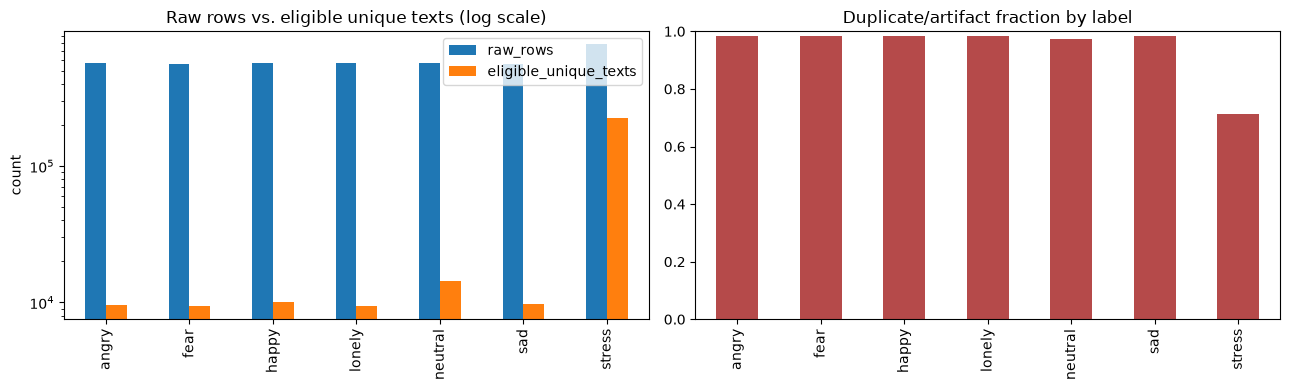

In [6]:
audit_table = pd.DataFrame({
    "raw_rows": pd.Series(audit["raw_label_counts"]),
    "eligible_unique_texts": pd.Series(audit["eligible_unique_by_label"]),
}).reindex(LABELS)
audit_table["duplicate_or_removed_fraction"] = (
    1 - audit_table["eligible_unique_texts"] / audit_table["raw_rows"]
)
display(audit_table)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
audit_table[["raw_rows", "eligible_unique_texts"]].plot.bar(
    ax=axes[0], logy=True, title="Raw rows vs. eligible unique texts (log scale)"
)
audit_table["duplicate_or_removed_fraction"].plot.bar(
    ax=axes[1], color="#b54a4a", title="Duplicate/artifact fraction by label"
)
axes[1].set_ylim(0, 1)
axes[0].set_ylabel("count")
plt.tight_layout()

if audit["conflicting_keys_excluded"]:
    warnings.warn(
        f'{audit["conflicting_keys_excluded"]:,} exact-text keys have conflicting labels '
        "and will be excluded."
    )
assert (audit_table["eligible_unique_texts"] > 0).all(), (
    "At least one label has no eligible unique text after cleaning."
)

## 4. Load every eligible exact-unique text

No per-class cap is applied here. Every valid exact-unique text is loaded before near-duplicate removal. This cell reports the natural cleaned class distribution.

In [7]:
records = []
query = """
    SELECT dedup_key, model_text, raw_example, label_mask, copies,
           suffix_copies, first_id, first_file
    FROM texts
    WHERE (label_mask & (label_mask - 1)) = 0
    ORDER BY dedup_key
"""
for key, text, raw_example, mask, copies, suffix_copies, source_id, source_file in db.execute(query):
    label = id2label[int(mask).bit_length() - 1]
    records.append({
        "text_key": key,
        "text": text,
        "raw_example": raw_example,
        "label": label,
        "original_copies": copies,
        "suffix_copies": suffix_copies,
        "source_id": source_id,
        "source_file": source_file,
    })
corpus = pd.DataFrame(records)
db.close()

assert corpus["text_key"].is_unique
assert set(corpus["label"]) == set(LABELS)
corpus_identity = {
    "pipeline_version": CFG.pipeline_version,
    "seed": CFG.seed,
    "rows": len(corpus),
}
corpus_fingerprint = hashlib.sha256(
    ("|".join(corpus["text_key"]) + "|" + json.dumps(corpus_identity, sort_keys=True))
    .encode("utf-8")
).hexdigest()
display(corpus.groupby("label").agg(
    exact_unique_texts=("text", "size"),
    median_characters=("text", lambda values: int(values.str.len().median())),
    max_original_copies=("original_copies", "max"),
))
print("Exact-unique corpus:", len(corpus))
print("Corpus fingerprint:", corpus_fingerprint)

,exact_unique_texts,median_characters,max_original_copies
label,,,
angry,9578,298,20409
fear,9386,300,20409
happy,10152,279,20409
lonely,9438,306,20409
neutral,14454,104,20409
sad,9791,291,20409
stress,224485,372,25386


Exact-unique corpus: 287284
Corpus fingerprint: 154501bf868e54b0d81ec618792e3387ffdf49e4c1cdd79c35d5eb722d7c3f42


## 5. Near-duplicate removal and class balancing

Exact deduplication cannot detect lightly rewritten generated templates. Within each label, MinHash proposes similar character-5-gram candidates; exact Jaccard similarity verifies every proposed merge. Connected components define near-duplicate families.

One deterministic representative is retained from each family. All near-unique examples from the six non-stress labels are retained. Only the oversized `stress` label is deterministically capped at the size of the largest non-stress label. No artificial duplicate is created.

This stage can take time on the full corpus. Its result is cached by corpus fingerprint and configuration.

In [8]:
from datasketch import MinHash, MinHashLSH

NEAR_GROUP_PATH = OUT / "near_duplicate_groups.parquet"
NEAR_META_PATH = OUT / "near_duplicate_meta.json"
near_meta = {
    "corpus_fingerprint": corpus_fingerprint,
    "threshold": CFG.near_duplicate_threshold,
    "shingle_size": CFG.shingle_size,
    "minhash_permutations": CFG.minhash_permutations,
}
near_cache_valid = (
    NEAR_GROUP_PATH.exists()
    and NEAR_META_PATH.exists()
    and json.loads(NEAR_META_PATH.read_text(encoding="utf-8")) == near_meta
)

NUMBER_RE = re.compile(r"[0-9០-៩]+")
def character_shingles(text, size=CFG.shingle_size):
    normalized = canonical_key(NUMBER_RE.sub("<NUM>", text))
    if len(normalized) <= size:
        return {normalized}
    return {normalized[i:i + size] for i in range(len(normalized) - size + 1)}

if near_cache_valid and not CFG.force_rebuild_near_duplicates:
    near_groups = pd.read_parquet(NEAR_GROUP_PATH)
    corpus = corpus.drop(columns=["near_duplicate_group"], errors="ignore").merge(
        near_groups, on="text_key", how="left", validate="one_to_one"
    )
    print("Reused validated near-duplicate groups.")
else:
    parent = list(range(len(corpus)))
    rank = [0] * len(corpus)

    def find(item):
        while parent[item] != item:
            parent[item] = parent[parent[item]]
            item = parent[item]
        return item

    def union(a, b):
        root_a, root_b = find(a), find(b)
        if root_a == root_b:
            return
        if rank[root_a] < rank[root_b]:
            root_a, root_b = root_b, root_a
        parent[root_b] = root_a
        if rank[root_a] == rank[root_b]:
            rank[root_a] += 1

    candidate_pairs = 0
    verified_pairs = 0
    for label in LABELS:
        label_positions = np.flatnonzero(corpus["label"].to_numpy() == label)
        lsh = MinHashLSH(
            threshold=CFG.near_duplicate_threshold,
            num_perm=CFG.minhash_permutations,
        )
        for position in tqdm(label_positions, desc=f"Near duplicates: {label}"):
            shingles = character_shingles(corpus.iloc[position]["text"])
            signature = MinHash(num_perm=CFG.minhash_permutations, seed=CFG.seed)
            for shingle in sorted(shingles):
                signature.update(shingle.encode("utf-8"))
            for candidate_name in lsh.query(signature):
                candidate = int(candidate_name)
                candidate_pairs += 1
                other = character_shingles(corpus.iloc[candidate]["text"])
                similarity = len(shingles & other) / len(shingles | other)
                if similarity >= CFG.near_duplicate_threshold:
                    union(position, candidate)
                    verified_pairs += 1
            lsh.insert(str(position), signature)

    components = {}
    for position in range(len(corpus)):
        components.setdefault(find(position), []).append(position)
    group_ids = {}
    for members in components.values():
        stable_keys = sorted(corpus.iloc[members]["text_key"])
        group_id = hashlib.sha1("|".join(stable_keys).encode("utf-8")).hexdigest()
        for member in members:
            group_ids[member] = group_id
    corpus["near_duplicate_group"] = [
        group_ids[position] for position in range(len(corpus))
    ]
    corpus[["text_key", "near_duplicate_group"]].to_parquet(
        NEAR_GROUP_PATH, index=False
    )
    NEAR_META_PATH.write_text(json.dumps(near_meta, indent=2), encoding="utf-8")
    print(f"Candidate pairs: {candidate_pairs:,}; verified pairs: {verified_pairs:,}")

def stable_priority(key, seed=CFG.seed):
    return int.from_bytes(
        hashlib.blake2b(f"{seed}|{key}".encode("utf-8"), digest_size=8).digest(),
        "big",
    )

corpus["selection_priority"] = corpus["text_key"].map(stable_priority)
near_unique = (
    corpus.sort_values(["near_duplicate_group", "selection_priority"])
    .drop_duplicates("near_duplicate_group", keep="first")
    .copy()
)
near_counts = near_unique["label"].value_counts().reindex(LABELS)
NON_STRESS_LABELS = [label for label in LABELS if label != "stress"]
STRESS_CAP = int(near_counts.loc[NON_STRESS_LABELS].max())

retained_parts = []
for label in LABELS:
    label_rows = near_unique.loc[near_unique["label"] == label].sort_values(
        "selection_priority"
    )
    if label == "stress":
        label_rows = label_rows.head(STRESS_CAP)
    retained_parts.append(label_rows)
sample = (
    pd.concat(retained_parts, ignore_index=True)
    .sort_values(["label", "selection_priority"])
    .reset_index(drop=True)
)
retained_counts = sample["label"].value_counts().reindex(LABELS)
assert sample["text_key"].is_unique
assert sample["near_duplicate_group"].is_unique
assert retained_counts["stress"] <= STRESS_CAP
assert retained_counts.loc[NON_STRESS_LABELS].equals(
    near_counts.loc[NON_STRESS_LABELS]
)

sample_identity = {
    "pipeline_version": CFG.pipeline_version,
    "corpus_fingerprint": corpus_fingerprint,
    "near_duplicate_threshold": CFG.near_duplicate_threshold,
    "stress_cap": STRESS_CAP,
    "retained_counts": retained_counts.to_dict(),
}
sample_fingerprint = hashlib.sha256(
    ("|".join(sample["text_key"]) + "|" + json.dumps(sample_identity, sort_keys=True))
    .encode("utf-8")
).hexdigest()

near_unique.to_parquet(OUT / "near_unique_corpus.parquet", index=False)
sample.to_parquet(OUT / "balanced_benchmark.parquet", index=False)
print("Exact-unique rows:", len(corpus))
print("Near-unique rows:", len(near_unique))
print("Near-unique counts:", near_counts.to_dict())
print("Stress cap:", STRESS_CAP)
print("Retained counts:", retained_counts.to_dict())
print("Final approximately balanced benchmark:", len(sample))
print("Benchmark fingerprint:", sample_fingerprint)

Reused validated near-duplicate groups.
Exact-unique rows: 287284
Near-unique rows: 8898
Near-unique counts: {'angry': 919, 'fear': 782, 'happy': 1366, 'lonely': 801, 'neutral': 1127, 'sad': 1197, 'stress': 2706}
Stress cap: 1366
Retained counts: {'angry': 919, 'fear': 782, 'happy': 1366, 'lonely': 801, 'neutral': 1127, 'sad': 1197, 'stress': 1366}
Final approximately balanced benchmark: 7558
Benchmark fingerprint: 77055d83fd65602efe830107c03cff890e65ba2363e97ff2255ec46ba822c0f5


### Near-duplicate and balance audit

Inspect the largest families before accepting the benchmark. The report must state the exact threshold, texts removed as near duplicates, per-label counts before capping, the stress cap, and final retained counts.

In [9]:
group_summary = (
    corpus.groupby("near_duplicate_group")
    .agg(size=("text_key", "size"), label=("label", "first"))
    .sort_values("size", ascending=False)
)
print(
    f"Near-duplicate families: {len(group_summary):,}; "
    f"singletons: {group_summary['size'].eq(1).sum():,}; "
    f"largest family: {group_summary['size'].max():,}"
)
display(group_summary["size"].value_counts().sort_index().head(25).rename(
    "number_of_families"
).to_frame())
largest = group_summary.head(10).index
display(
    corpus.loc[corpus["near_duplicate_group"].isin(largest),
               ["near_duplicate_group", "label", "text"]]
    .sort_values(["near_duplicate_group", "text"])
    .head(60)
)
balance_audit = pd.DataFrame({
    "exact_unique": corpus["label"].value_counts(),
    "near_unique": near_counts,
    "retained_for_modeling": retained_counts,
}).reindex(LABELS)
balance_audit["removed_near_duplicate"] = (
    balance_audit["exact_unique"] - balance_audit["near_unique"]
)
balance_audit["removed_for_balance"] = (
    balance_audit["near_unique"] - balance_audit["retained_for_modeling"]
)
display(balance_audit)
balance_audit.to_csv(OUT / "balance_audit.csv")

Near-duplicate families: 8,898; singletons: 3,415; largest family: 100,000


,number_of_families
size,
1,3415
2,742
3,593
4,708
5,174
6,251
7,155
8,184
9,154


,near_duplicate_group,label,text
40197,00e8e6fcf3966a98b63856786342a209c94e11c3,stress,ខ្ញុំមានអារម្មណ៍ថាស្ត្រេសខ្លាំងណាស់ក្នុងមួយរយៈ...
40198,00e8e6fcf3966a98b63856786342a209c94e11c3,stress,ខ្ញុំមានអារម្មណ៍ថាស្ត្រេសខ្លាំងណាស់ក្នុងមួយរយៈ...
40199,00e8e6fcf3966a98b63856786342a209c94e11c3,stress,ខ្ញុំមានអារម្មណ៍ថាស្ត្រេសខ្លាំងណាស់ក្នុងមួយរយៈ...
40200,00e8e6fcf3966a98b63856786342a209c94e11c3,stress,ខ្ញុំមានអារម្មណ៍ថាស្ត្រេសខ្លាំងណាស់ក្នុងមួយរយៈ...
40201,00e8e6fcf3966a98b63856786342a209c94e11c3,stress,ខ្ញុំមានអារម្មណ៍ថាស្ត្រេសខ្លាំងណាស់ក្នុងមួយរយៈ...
40202,00e8e6fcf3966a98b63856786342a209c94e11c3,stress,ខ្ញុំមានអារម្មណ៍ថាស្ត្រេសខ្លាំងណាស់ក្នុងមួយរយៈ...
40203,00e8e6fcf3966a98b63856786342a209c94e11c3,stress,ខ្ញុំមានអារម្មណ៍ថាស្ត្រេសខ្លាំងណាស់ក្នុងមួយរយៈ...
40204,00e8e6fcf3966a98b63856786342a209c94e11c3,stress,ខ្ញុំមានអារម្មណ៍ថាស្ត្រេសខ្លាំងណាស់ក្នុងមួយរយៈ...
40205,00e8e6fcf3966a98b63856786342a209c94e11c3,stress,ខ្ញុំមានអារម្មណ៍ថាស្ត្រេសខ្លាំងណាស់ក្នុងមួយរយៈ...
40206,00e8e6fcf3966a98b63856786342a209c94e11c3,stress,ខ្ញុំមានអារម្មណ៍ថាស្ត្រេសខ្លាំងណាស់ក្នុងមួយរយៈ...


,exact_unique,near_unique,retained_for_modeling,removed_near_duplicate,removed_for_balance
label,,,,,
angry,9578,919,919,8659,0
fear,9386,782,782,8604,0
happy,10152,1366,1366,8786,0
lonely,9438,801,801,8637,0
neutral,14454,1127,1127,13327,0
sad,9791,1197,1197,8594,0
stress,224485,2706,1366,221779,1340


## 6. Final train/validation/test split

Every record retained by the approximate-balancing policy is assigned exactly once:

- 80% training;
- 10% validation;
- 10% testing.

The split is stratified by label and reproducible. Because one representative per near-duplicate family was retained, no family can cross partitions.

In [10]:
train_index, holdout_index = train_test_split(
    sample.index,
    test_size=0.20,
    stratify=sample["label"],
    random_state=CFG.seed,
)
validation_index, test_index = train_test_split(
    holdout_index,
    test_size=0.50,
    stratify=sample.loc[holdout_index, "label"],
    random_state=CFG.seed + 1,
)
sample["split"] = "train"
sample.loc[validation_index, "split"] = "validation"
sample.loc[test_index, "split"] = "test"

assert sample["split"].notna().all()
assert sample["text_key"].is_unique
assert sample.groupby("near_duplicate_group")["split"].nunique().max() == 1

split_table = pd.crosstab(sample["split"], sample["label"]).reindex(
    index=["train", "validation", "test"], columns=LABELS, fill_value=0
)
display(split_table)
display((split_table / split_table.sum()).round(4).rename_axis("split_fraction"))

split_columns = [
    "text_key", "text", "label", "near_duplicate_group", "split",
    "source_id", "source_file", "original_copies", "suffix_copies",
]
sample[split_columns].to_parquet(OUT / "frozen_experiment_split.parquet", index=False)

label,angry,fear,happy,lonely,neutral,sad,stress
split,,,,,,,
train,735,626,1093,641,901,957,1093
validation,92,78,136,80,113,120,137
test,92,78,137,80,113,120,136


label,angry,fear,happy,lonely,neutral,sad,stress
split_fraction,,,,,,,
train,0.7998,0.8005,0.8001,0.8002,0.7995,0.7995,0.8001
validation,0.1001,0.0997,0.0996,0.0999,0.1003,0.1003,0.1003
test,0.1001,0.0997,0.1003,0.0999,0.1003,0.1003,0.0996


## 7. CLAWS tokenization with resumable checkpoints

CLAWS exposes single-text segmentation, so tokenization is sequential by default. This implementation:

- shows progress;
- prints an ETA after the first 100 new texts;
- commits every configured checkpoint;
- resumes after interruption;
- invalidates the cache when sample, cleaning pipeline, or CLAWS version changes.

If interrupted, rerun this cell; completed keys remain saved.

In [11]:
# claws-tokenizer 0.1.2 does not specify UTF-8 when it opens its Khmer
# vocabulary. This narrow wrapper makes the import portable on Windows,
# where Python otherwise defaults to cp1252 and raises UnicodeDecodeError.
import builtins
_standard_open = builtins.open
def _open_claws_vocab_utf8(file, mode="r", *args, **kwargs):
    is_claws_vocab = (
        str(file).replace("\\", "/").endswith("claws_tokenizer/models/vocab.json")
        and "b" not in mode
    )
    if is_claws_vocab:
        kwargs.setdefault("encoding", "utf-8")
    return _standard_open(file, mode, *args, **kwargs)

builtins.open = _open_claws_vocab_utf8
try:
    from claws_tokenizer import segment
finally:
    builtins.open = _standard_open

claws_version = metadata.version("claws-tokenizer")
TOKEN_DB_PATH = OUT / "claws_tokens.sqlite"
TOKEN_META_PATH = OUT / "claws_token_cache_meta.json"
token_meta = {
    "sample_fingerprint": sample_fingerprint,
    "pipeline_version": CFG.pipeline_version,
    "claws_version": claws_version,
}
token_cache_valid = (
    TOKEN_DB_PATH.exists()
    and TOKEN_META_PATH.exists()
    and json.loads(TOKEN_META_PATH.read_text(encoding="utf-8")) == token_meta
)
if CFG.force_retokenize or not token_cache_valid:
    for suffix in ("", "-wal", "-shm"):
        candidate = Path(str(TOKEN_DB_PATH) + suffix)
        if candidate.exists():
            candidate.unlink()
    TOKEN_META_PATH.write_text(json.dumps(token_meta, indent=2), encoding="utf-8")

token_db = sqlite3.connect(TOKEN_DB_PATH)
token_db.execute("PRAGMA journal_mode=WAL")
token_db.execute("""
    CREATE TABLE IF NOT EXISTS tokens (
        text_key TEXT PRIMARY KEY,
        text_sha256 TEXT NOT NULL,
        tokens_json TEXT NOT NULL
    )
""")
existing_keys = {
    row[0] for row in token_db.execute("SELECT text_key FROM tokens")
}
missing = sample.loc[~sample["text_key"].isin(existing_keys), ["text_key", "text"]]
print(
    f"CLAWS {claws_version}: {len(existing_keys & set(sample.text_key)):,} cached; "
    f"{len(missing):,} remaining."
)

started = time.perf_counter()
completed_now = 0
try:
    for row in tqdm(missing.itertuples(index=False), total=len(missing), desc="CLAWS"):
        tokens = [token.strip() for token in segment(row.text) if token.strip()]
        if not tokens:
            raise RuntimeError(f"CLAWS returned no tokens for key {row.text_key}")
        text_sha256 = hashlib.sha256(row.text.encode("utf-8")).hexdigest()
        token_db.execute(
            "INSERT OR REPLACE INTO tokens VALUES (?, ?, ?)",
            (row.text_key, text_sha256, json.dumps(tokens, ensure_ascii=False)),
        )
        completed_now += 1
        if completed_now % CFG.token_checkpoint_every == 0:
            token_db.commit()
        if completed_now == min(100, len(missing)) and completed_now:
            elapsed = time.perf_counter() - started
            seconds_per_text = elapsed / completed_now
            remaining_minutes = seconds_per_text * (len(missing) - completed_now) / 60
            print(
                f"Observed {seconds_per_text:.3f} seconds/text; "
                f"estimated remaining time {remaining_minutes:.1f} minutes."
            )
finally:
    token_db.commit()

token_rows = pd.read_sql_query(
    "SELECT text_key, text_sha256, tokens_json FROM tokens", token_db
)
token_db.execute("PRAGMA wal_checkpoint(TRUNCATE)")
token_db.close()

sample = sample.drop(columns=["tokens", "tokenized_text"], errors="ignore").merge(
    token_rows, on="text_key", how="left", validate="one_to_one"
)
if sample["tokens_json"].isna().any():
    missing_count = int(sample["tokens_json"].isna().sum())
    raise RuntimeError(
        f"{missing_count} texts are not tokenized. Rerun this cell to resume."
    )
expected_text_hash = sample["text"].map(
    lambda text: hashlib.sha256(text.encode("utf-8")).hexdigest()
)
if not expected_text_hash.equals(sample["text_sha256"]):
    raise RuntimeError("Token cache contains stale text values.")

sample["tokens"] = sample["tokens_json"].map(json.loads)
sample["tokenized_text"] = sample["tokens"].map(" ".join)
sample = sample.drop(columns=["tokens_json", "text_sha256"])
display(sample[["text", "tokenized_text", "label"]].sample(
    min(20, len(sample)), random_state=CFG.seed
))
print("Token count percentiles:", sample["tokens"].map(len).quantile(
    [0, .25, .5, .75, .9, .95, .99, 1]
).to_dict())

CLAWS 0.1.2: 7,558 cached; 0 remaining.


CLAWS: 0it [00:00, ?it/s]

,text,tokenized_text,label
3148,ខ្ញុំដើរកាត់ហ្វូងមនុស្សដ៏ច្រើនតែគ្មានអ្នកស្គាល...,ខ្ញុំ ដើរ កាត់ ហ្វូង មនុស្ស ដ៏ ច្រើនតែ គ្មាន អ...,lonely
1662,កាលពីម្សិលមិញ រាល់ពេលមានការឈរនៅកន្លែងខ្ពស់ខ្ញុ...,កាលពី ម្សិលមិញ រាល់ ពេល មាន ការឈរ នៅ កន្លែង ខ្...,fear
3078,ពេលខ្លះ ខ្ញុំមានអារម្មណ៍ថាមិនមានអ្នកណាម្នាក់យល...,ពេល ខ្លះ ខ្ញុំ មានអារម្មណ៍ ថា មិន មាន អ្នកណា ម...,lonely
3012,ការងាររបស់ខ្ញុំជោគជ័យហើយ ថ្ងៃនេះចៅហ្វាយនាយសរសើ...,ការងារ របស់ ខ្ញុំ ជោគជ័យ ហើយ ថ្ងៃ នេះ ចៅហ្វាយ ...,happy
3332,អារម្មណ៍ឯកោបុកមករកខ្ញុំម្តងទៀតហើយ ពេលដែលគ្មានម...,អារម្មណ៍ ឯកោបុក មករក ខ្ញុំ ម្តង ទៀត ហើយ ពេល ដែ...,lonely
4905,ក្នុងរយៈពេលប៉ុន្មានថ្ងៃចុងក្រោយនេះ ថ្ងៃនេះខ្ញុ...,ក្នុង រយៈពេល ប៉ុន្មាន ថ្ងៃ ចុងក្រោយ នេះ ថ្ងៃ ន...,neutral
3931,អ្នកគ្រប់គ្នា គឺការស្តាប់តន្ត្រីស្រទន់និងការសម...,អ្នកគ្រប់ គ្នា គឺ ការស្តាប់ តន្ត្រីស្រទន់ និង ...,neutral
7100,ជីវិតរបស់ខ្ញុំពេលនេះពោរពេញដោយភាពតានតឹង និងសម្ព...,ជីវិត របស់ ខ្ញុំ ពេលនេះ ពោរពេញ ដោយ ភាពតានតឹង ន...,stress
2874,ពេលថ្មីៗនេះ ពេលមានការទទួលបានលិខិតអបអរសាទរខ្ញុំ...,ពេល ថ្មី ៗ នេះ ពេល មាន ការទទួលបាន លិខិត អបអរសា...,happy
1730,គ្មានអ្វីអាចពិពណ៌នាអំពីលទ្ធផលល្អ និងភាពសប្បាយរ...,គ្មាន អ្វី អាច ពិពណ៌នា អំពី លទ្ធផល ល្អ និង ភាព...,happy


Token count percentiles: {0.0: 4.0, 0.25: 14.0, 0.5: 19.0, 0.75: 34.0, 0.9: 76.0, 0.95: 81.0, 0.99: 88.0, 1.0: 95.0}


## 8. Majority baseline and CLAWS word TF–IDF + linear SVM

CLAWS segments Khmer words. Word unigrams/bigrams are converted to TF–IDF. The vectorizer is fitted on training text only; validation macro F1 selects `C`; the frozen test set is evaluated once.

The retained classes are only moderately imbalanced. Macro F1 is the primary metric so every label contributes equally to evaluation.

In [12]:
def metric_row(y_true, y_pred):
    precision, recall, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=LABELS, average="macro", zero_division=0
    )
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision,
        "recall_macro": recall,
        "f1_macro": macro_f1,
        "f1_weighted": f1_score(
            y_true, y_pred, labels=LABELS, average="weighted", zero_division=0
        ),
    }

parts = {
    name: sample.loc[sample["split"] == name].copy()
    for name in ["train", "validation", "test"]
}
vectorizer = TfidfVectorizer(
    tokenizer=str.split, preprocessor=None, token_pattern=None, lowercase=False,
    ngram_range=(1, 2), min_df=2, max_df=0.98, max_features=300_000,
    sublinear_tf=True, dtype=np.float32,
)
x_train = vectorizer.fit_transform(parts["train"]["tokenized_text"])
x_validation = vectorizer.transform(parts["validation"]["tokenized_text"])
x_test = vectorizer.transform(parts["test"]["tokenized_text"])

tuning_rows = []
candidates = {}
for c_value in CFG.svm_c_values:
    candidate = LinearSVC(C=c_value, random_state=CFG.seed)
    candidate.fit(x_train, parts["train"]["label"])
    validation_prediction = candidate.predict(x_validation)
    tuning_rows.append({
        "C": c_value,
        **metric_row(parts["validation"]["label"], validation_prediction),
    })
    candidates[c_value] = candidate
tuning = pd.DataFrame(tuning_rows).sort_values(
    ["f1_macro", "C"], ascending=[False, True]
).reset_index(drop=True)
best_c = float(tuning.iloc[0]["C"])
model = candidates[best_c]
test_prediction = model.predict(x_test)

majority = DummyClassifier(strategy="most_frequent")
majority.fit(np.zeros((len(parts["train"]), 1)), parts["train"]["label"])
majority_prediction = majority.predict(np.zeros((len(parts["test"]), 1)))

primary = {
    "parts": parts, "vectorizer": vectorizer, "model": model,
    "best_c": best_c, "tuning": tuning, "x_train": x_train,
    "x_test": x_test, "test_prediction": test_prediction,
    "majority_prediction": majority_prediction,
}
display(tuning)
classical_results = pd.DataFrame([
    {"model": "Majority", **metric_row(parts["test"]["label"], majority_prediction)},
    {"model": "CLAWS word TF-IDF + linear SVM",
     **metric_row(parts["test"]["label"], test_prediction)},
])
display(classical_results.sort_values("f1_macro", ascending=False))
classical_results.to_csv(OUT / "classical_results.csv", index=False)
tuning.to_csv(OUT / "svm_validation_tuning.csv", index=False)
joblib.dump({
    "pipeline_version": CFG.pipeline_version, "labels": LABELS,
    "claws_version": claws_version, "vectorizer": vectorizer,
    "model": model, "best_c": best_c,
}, OUT / "claws_tfidf_svm.joblib")

,C,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
0,1.0,1.000000,1.000000,1.000000,1.000000,1.000000
1,10.0,0.998677,0.998819,0.998736,0.998772,0.998677
2,0.1,0.994709,0.993894,0.994643,0.994234,0.994702


,model,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
1,CLAWS word TF-IDF + linear SVM,0.998677,0.998236,0.998447,0.998332,0.998678
0,Majority,0.181217,0.025888,0.142857,0.043833,0.055603


['/Users/thisisnotleng/Desktop/AUPP/NLP/Pilot Test Final/artifacts_professional/balanced-near-v2/claws_tfidf_svm.joblib']

### Primary classical-model diagnostics

Per-class metrics and the confusion matrix are computed only after the validation-selected model is fixed. Feature inspection is descriptive and must not be used to tune against the test set.

,precision,recall,f1-score,support
angry,1.000000,0.989130,0.994536,92.000000
fear,1.000000,1.000000,1.000000,78.000000
happy,1.000000,1.000000,1.000000,137.000000
lonely,0.987654,1.000000,0.993789,80.000000
neutral,1.000000,1.000000,1.000000,113.000000
sad,1.000000,1.000000,1.000000,120.000000
stress,1.000000,1.000000,1.000000,136.000000
accuracy,0.998677,0.998677,0.998677,0.998677
macro avg,0.998236,0.998447,0.998332,756.000000
weighted avg,0.998694,0.998677,0.998678,756.000000


,angry,fear,happy,lonely,neutral,sad,stress
0,ខឹង,ខ្លាច,ទទួលបាន,ម្នាក់,ធម្មតា,ទឹកភ្នែក,សម្ពាធ
1,ខឹង ខ្លាំង,ភ័យ,រីករាយ,ឯកា,មិន មាន,ចង់ នៅ,តានតឹង
2,ខ្ញុំ ខឹង,ភ័យខ្លាច,សប្បាយចិត្ត,ឯកោ,ស្ងប់ស្ងាត់,យំ,ចាប់តាំងពី មាន
3,ដកដង្ហើម ខ្លាំង,ហ៊ាន,ស្រស់ស្រាយ,ចង់ មាន,កាហ្វេ,សោកសៅ,ថប់
4,ទង្វើ,មិន ហ៊ាន,ញញឹម,ឯកោ ខ្លាំង,នេះ ខ្ញុំ,ខូចចិត្ត,ពេក
5,ក្តៅ,ខ្ញុំ ភ័យ,រំភើបចិត្ត,គេ បោះបង់ចោល,ទៅតាម,ឈឺចាប់,និង
6,បញ្ហា ជាមួយ,ព្រួយបារម្ភ ខ្លាំង,ពិតជា មាន,ម្នាក់ឯង,ជាធម្មតា,ការបាត់បង់,សម្រាក
7,មិន គោរព,សុវត្ថិភាព,ខ្ញុំ សប្បាយចិត្ត,ខ្ញុំ ទេ,ថ្ងៃ,ពិបាកចិត្ត,ស្ត្រេស
8,គោរព,ភាពភ័យខ្លាច,ជោគជ័យ,ឆ្ងាយ,អារម្មណ៍ សប្បាយ,ពិបាកចិត្ត ណាស់,ក្បាល
9,កុំ,ព្រួយបារម្ភ,បាន,ស្ងាត់ស្ងៀម,ព្រឹក,ការធ្លាក់ការប្រឡង,ច្រើន ពេក


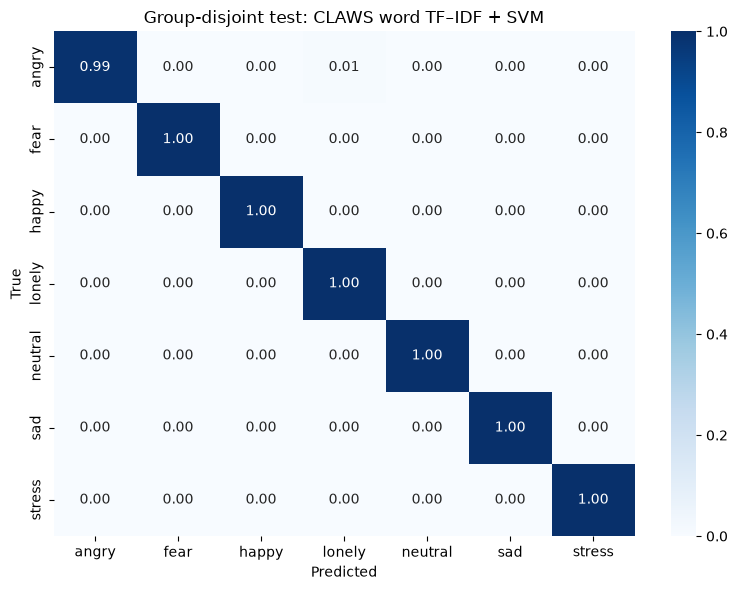

In [13]:
primary_test = primary["parts"]["test"].copy()
primary_test["claws_svm_prediction"] = primary["test_prediction"]

svm_report = pd.DataFrame(
    classification_report(
        primary_test["label"],
        primary_test["claws_svm_prediction"],
        labels=LABELS,
        output_dict=True,
        zero_division=0,
    )
).T
display(svm_report)
svm_report.to_csv(OUT / "claws_svm_classification_report.csv")

matrix = confusion_matrix(
    primary_test["label"],
    primary_test["claws_svm_prediction"],
    labels=LABELS,
    normalize="true",
)
plt.figure(figsize=(8, 6))
sns.heatmap(
    matrix, annot=True, fmt=".2f", cmap="Blues",
    xticklabels=LABELS, yticklabels=LABELS,
)
plt.title("Group-disjoint test: CLAWS word TF–IDF + SVM")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.savefig(OUT / "claws_svm_confusion_matrix.png", dpi=180, bbox_inches="tight")

feature_names = np.asarray(primary["vectorizer"].get_feature_names_out())
top_features = {}
for class_index, label in enumerate(primary["model"].classes_):
    best = np.argsort(primary["model"].coef_[class_index])[-15:][::-1]
    top_features[label] = feature_names[best]
display(pd.DataFrame(top_features))

## 9. XLM-RoBERTa on the identical primary split

XLM-R receives `text`, not CLAWS tokens. Its own tokenizer is used. Before training, the notebook reports token-length percentiles and the proportion that will be truncated.

The final configuration trains for three epochs and records hardware, runtime, token lengths, and truncation. Training checkpoints are reused automatically after interruption, so rerunning the notebook does not restart XLM-R from zero.

In [ ]:
trainer = None
xlmr_test_prediction = None
xlmr_runtime_minutes = None
xlmr_history = None

if CFG.run_xlmr:
    import torch
    from datasets import Dataset, DatasetDict
    from transformers import (
        AutoModelForSequenceClassification,
        AutoTokenizer,
        DataCollatorWithPadding,
        EarlyStoppingCallback,
        Trainer,
        TrainingArguments,
        set_seed,
    )
    from transformers.trainer_utils import get_last_checkpoint

    set_seed(CFG.seed)
    device_name = (
        "cuda" if torch.cuda.is_available()
        else "mps" if torch.backends.mps.is_available()
        else "cpu"
    )
    print("Transformer device:", device_name)
    if device_name == "cuda":
        print("GPU:", torch.cuda.get_device_name(0))
        print("CUDA runtime:", torch.version.cuda)
        torch.backends.cudnn.benchmark = True
    print("Torch:", torch.__version__, "| Transformers:", metadata.version("transformers"))

    tokenizer = AutoTokenizer.from_pretrained(CFG.xlmr_model, use_fast=True)
    token_lengths = []
    for start in tqdm(range(0, len(sample), 512), desc="XLM-R length audit"):
        batch_text = sample["text"].iloc[start:start + 512].tolist()
        encoded_batch = tokenizer(
            batch_text, add_special_tokens=True, truncation=False
        )
        token_lengths.extend(map(len, encoded_batch["input_ids"]))
    token_lengths = np.asarray(token_lengths)
    print(
        "XLM-R token-length percentiles:",
        dict(zip(
            [50, 75, 90, 95, 99, 100],
            np.percentile(token_lengths, [50, 75, 90, 95, 99, 100]).round(0),
        )),
    )
    print(
        f"Texts truncated at max_length={CFG.max_length}: "
        f"{np.mean(token_lengths > CFG.max_length):.2%}"
    )

    primary_parts = primary["parts"]
    hf_datasets = DatasetDict({
        name: Dataset.from_pandas(
            part[["text", "label"]].assign(
                label=part["label"].map(label2id).astype(int)
            ),
            preserve_index=False,
        )
        for name, part in primary_parts.items()
    })

    def encode_xlmr(batch):
        return tokenizer(
            batch["text"],
            truncation=True,
            max_length=CFG.max_length,
        )

    encoded_datasets = hf_datasets.map(
        encode_xlmr, batched=True, remove_columns=["text"]
    )

    def transformer_metrics(evaluation_prediction):
        predicted_ids = np.argmax(evaluation_prediction.predictions, axis=-1)
        true_labels = [
            id2label[int(value)] for value in evaluation_prediction.label_ids
        ]
        predicted_labels = [
            id2label[int(value)] for value in predicted_ids
        ]
        return metric_row(true_labels, predicted_labels)

    training_args = TrainingArguments(
        output_dir=str(OUT / "xlmr_checkpoints_rtx2060"),
        learning_rate=2e-5,
        per_device_train_batch_size=CFG.xlmr_batch_size,
        per_device_eval_batch_size=CFG.xlmr_batch_size * 2,
        gradient_accumulation_steps=CFG.xlmr_gradient_accumulation,
        num_train_epochs=CFG.xlmr_epochs,
        weight_decay=0.01,
        warmup_ratio=0.1,
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="steps",
        logging_steps=50,
        load_best_model_at_end=True,
        metric_for_best_model="f1_macro",
        greater_is_better=True,
        save_total_limit=2,
        fp16=torch.cuda.is_available(),
        fp16_full_eval=torch.cuda.is_available(),
        dataloader_pin_memory=device_name == "cuda",
        gradient_checkpointing=device_name == "cuda",
        optim="adafactor",
        eval_accumulation_steps=8,
        torch_empty_cache_steps=50,
        report_to="none",
        seed=CFG.seed,
        data_seed=CFG.seed,
    )
    xlmr_model = AutoModelForSequenceClassification.from_pretrained(
        CFG.xlmr_model,
        num_labels=len(LABELS),
        label2id=label2id,
        id2label=id2label,
    )
    xlmr_model.config.use_cache = False
    if device_name == "cuda":
        xlmr_model.gradient_checkpointing_enable()
    callbacks = []
    if CFG.xlmr_epochs >= 3:
        callbacks.append(EarlyStoppingCallback(early_stopping_patience=2))

    trainer = Trainer(
        model=xlmr_model,
        args=training_args,
        train_dataset=encoded_datasets["train"],
        eval_dataset=encoded_datasets["validation"],
        tokenizer=tokenizer,
        data_collator=DataCollatorWithPadding(tokenizer),
        compute_metrics=transformer_metrics,
        callbacks=callbacks,
    )

    checkpoint_dir = OUT / "xlmr_checkpoints_rtx2060"
    last_checkpoint = (
        get_last_checkpoint(str(checkpoint_dir))
        if checkpoint_dir.exists() else None
    )
    if last_checkpoint:
        print("Resuming XLM-R from:", last_checkpoint)

    started = time.perf_counter()
    trainer.train(resume_from_checkpoint=last_checkpoint)
    xlmr_runtime_minutes = (time.perf_counter() - started) / 60

    xlmr_output = trainer.predict(encoded_datasets["test"])
    xlmr_test_prediction = np.array([
        id2label[int(value)]
        for value in np.argmax(xlmr_output.predictions, axis=-1)
    ])
    xlmr_history = pd.DataFrame(trainer.state.log_history)
    xlmr_history.to_csv(OUT / "xlmr_training_history.csv", index=False)
    trainer.save_model(str(OUT / "xlmr_best"))
    tokenizer.save_pretrained(str(OUT / "xlmr_best"))
    print(f"XLM-R runtime: {xlmr_runtime_minutes:.1f} minutes")
else:
    print(
        "XLM-R intentionally skipped because CFG.run_xlmr=False. "
        "The final two-model comparison is incomplete without it."
    )

Transformer device: mps
Torch: 2.15.0 | Transformers: 4.57.6


XLM-R length audit:   0%|          | 0/15 [00:00<?, ?it/s]

XLM-R token-length percentiles: {50: np.float64(28.0), 75: np.float64(50.0), 90: np.float64(111.0), 95: np.float64(120.0), 99: np.float64(129.0), 100: np.float64(143.0)}
Texts truncated at max_length=192: 0.00%


Map:   0%|          | 0/6046 [00:00<?, ? examples/s]

Map:   0%|          | 0/756 [00:00<?, ? examples/s]

Map:   0%|          | 0/756 [00:00<?, ? examples/s]

Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at FacebookAI/xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/var/folders/1n/ldnnwmg97hqcxc8twgwhj_wr0000gn/T/ipykernel_8137/1616438309.py:115: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Epoch,Training Loss,Validation Loss


## 10. Final group-disjoint comparison and group-aware uncertainty

Confidence intervals resample near-duplicate groups, not individual rows. This respects the experimental unit better than an ordinary row bootstrap.

The paired interval reports `XLM-R macro F1 − CLAWS-SVM macro F1`. If it crosses zero, the held-out evidence does not establish a clear winner.

In [ ]:
final_predictions = {
    "Majority": np.asarray(primary["majority_prediction"]),
    "CLAWS word TF-IDF + linear SVM": np.asarray(primary["test_prediction"]),
}
if xlmr_test_prediction is not None:
    final_predictions["XLM-RoBERTa"] = np.asarray(xlmr_test_prediction)

y_test = primary_test["label"].to_numpy()
final_rows = [
    {"model": model_name, **metric_row(y_test, prediction)}
    for model_name, prediction in final_predictions.items()
]
final_results = (
    pd.DataFrame(final_rows)
    .sort_values("f1_macro", ascending=False)
    .reset_index(drop=True)
)
display(final_results)
final_results.to_csv(OUT / "final_results.csv", index=False)

def grouped_bootstrap_macro_f1(
    frame,
    prediction_a,
    prediction_b=None,
    repeats=BOOTSTRAP_REPEATS,
    seed=CFG.seed,
):
    rng = np.random.default_rng(seed)
    groups = frame["near_duplicate_group"].drop_duplicates().to_numpy()
    group_positions = {
        group: np.flatnonzero(frame["near_duplicate_group"].to_numpy() == group)
        for group in groups
    }
    truth = frame["label"].to_numpy()
    prediction_a = np.asarray(prediction_a)
    prediction_b = None if prediction_b is None else np.asarray(prediction_b)
    values = []

    for _ in tqdm(range(repeats), desc="Group bootstrap"):
        sampled_groups = rng.choice(groups, size=len(groups), replace=True)
        positions = np.concatenate([group_positions[group] for group in sampled_groups])
        score_a = f1_score(
            truth[positions],
            prediction_a[positions],
            labels=LABELS,
            average="macro",
            zero_division=0,
        )
        if prediction_b is None:
            values.append(score_a)
        else:
            score_b = f1_score(
                truth[positions],
                prediction_b[positions],
                labels=LABELS,
                average="macro",
                zero_division=0,
            )
            values.append(score_a - score_b)
    return np.percentile(values, [2.5, 50, 97.5])

svm_interval = grouped_bootstrap_macro_f1(
    primary_test, primary["test_prediction"]
)
print(
    "CLAWS-SVM macro-F1 group bootstrap [2.5%, median, 97.5%]:",
    np.round(svm_interval, 4),
)

comparison_interval = None
if xlmr_test_prediction is not None:
    comparison_interval = grouped_bootstrap_macro_f1(
        primary_test, xlmr_test_prediction, primary["test_prediction"]
    )
    print(
        "XLM-R minus CLAWS-SVM macro-F1 [2.5%, median, 97.5%]:",
        np.round(comparison_interval, 4),
    )

prediction_table = primary_test[
    ["text_key", "text", "label", "near_duplicate_group"]
].copy()
for model_name, prediction in final_predictions.items():
    prediction_table[model_name] = prediction
prediction_table.to_parquet(
    OUT / "group_disjoint_test_predictions.parquet", index=False
)

## 11. Leakage diagnostics and error analysis

This section asks whether held-out errors or successes are associated with unusually similar training texts. Similarity is computed in the fitted training TF–IDF space. It is a diagnostic, not a second test-set tuning opportunity.

In [ ]:
neighbors = NearestNeighbors(
    n_neighbors=1, metric="cosine", algorithm="brute", n_jobs=-1
)
neighbors.fit(primary["x_train"])
distance, neighbor_index = neighbors.kneighbors(primary["x_test"])
similarity = 1 - distance[:, 0]

train_part = primary["parts"]["train"].reset_index(drop=True)
diagnostics = primary_test.reset_index(drop=True)[
    ["text_key", "text", "label", "near_duplicate_group", "claws_svm_prediction"]
].copy()
diagnostics["nearest_train_text"] = train_part.iloc[
    neighbor_index[:, 0]
]["text"].to_numpy()
diagnostics["nearest_train_label"] = train_part.iloc[
    neighbor_index[:, 0]
]["label"].to_numpy()
diagnostics["cosine_similarity"] = similarity
diagnostics["correct"] = (
    diagnostics["label"] == diagnostics["claws_svm_prediction"]
)

for threshold in [0.80, 0.90, 0.95]:
    print(
        f"Test texts with nearest training cosine >= {threshold:.2f}: "
        f"{np.mean(similarity >= threshold):.2%}"
    )
display(diagnostics.sort_values("cosine_similarity", ascending=False).head(20))
display(
    diagnostics.loc[~diagnostics["correct"]]
    .sort_values("cosine_similarity", ascending=False)
    .head(30)
)
diagnostics.to_parquet(
    OUT / "leakage_and_error_diagnostics.parquet", index=False
)


## 12. Inference examples

These helpers apply conservative Unicode/whitespace normalization. The dataset-specific terminal-counter removal is intentionally not applied to genuine new messages, where a parenthesized number may be meaningful. SVM decision scores are margins, not calibrated probabilities.

In [ ]:
def validate_inference_text(text):
    if not isinstance(text, str):
        raise TypeError("text must be a string")
    normalized = normalize_base(text)
    if not normalized or not KHMER_RE.search(normalized):
        raise ValueError("Enter non-empty text containing Khmer characters.")
    return normalized

def predict_claws_svm(text):
    normalized = validate_inference_text(text)
    tokenized = " ".join(
        token.strip() for token in segment(normalized) if token.strip()
    )
    prediction = primary["model"].predict(
        primary["vectorizer"].transform([tokenized])
    )[0]
    return str(prediction)

def predict_xlmr(text):
    if trainer is None:
        raise RuntimeError("XLM-R has not been trained in this run.")
    import torch
    normalized = validate_inference_text(text)
    encoded = tokenizer(
        normalized,
        return_tensors="pt",
        truncation=True,
        max_length=CFG.max_length,
    )
    encoded = {key: value.to(trainer.model.device) for key, value in encoded.items()}
    with torch.no_grad():
        logits = trainer.model(**encoded).logits
    return id2label[int(logits.argmax(dim=-1).item())]

# Replace with genuinely unseen Khmer text:
predict_claws_svm("ខ្ញុំបែកគ្នាហើយ")

## 13. Completion status and reporting checklist

A complete submission must include:

- full cleaning and exact-deduplication audit;
- verified near-duplicate method and reviewed family examples;
- balance audit showing what was removed and why;
- frozen 80/10/10 split using every selected balanced record;
- CLAWS version and statistical preprocessing explanation;
- validation-selected SVM and held-out metrics;
- completed XLM-R fine-tuning on the identical split;
- accuracy, macro/weighted F1, per-class metrics, confusion matrices, and errors;
- hardware, runtime, versions, truncation rate, and seed;
- limitations: generated/template-heavy source data and absence of an external human-reviewed test set;
- installation instructions and a reproducible run order at the top.

Do not describe benchmark performance as real-world accuracy.

In [ ]:
run_status = {
    "pipeline_version": CFG.pipeline_version,
    "exact_unique_rows": len(corpus),
    "near_unique_rows": len(near_unique),
    "stress_cap": STRESS_CAP,
    "retained_counts": retained_counts.to_dict(),
    "retained_benchmark_rows": len(sample),
    "split_frozen": (OUT / "frozen_experiment_split.parquet").exists(),
    "claws_complete": True,
    "xlmr_complete": xlmr_test_prediction is not None,
    "final_comparison_complete": xlmr_test_prediction is not None,
    "xlmr_runtime_minutes": xlmr_runtime_minutes,
    "svm_group_bootstrap": np.asarray(svm_interval).tolist(),
    "xlmr_minus_svm_group_bootstrap": (
        None if comparison_interval is None
        else np.asarray(comparison_interval).tolist()
    ),
}
print(json.dumps(run_status, indent=2))
(OUT / "run_status.json").write_text(
    json.dumps(run_status, indent=2), encoding="utf-8"
)
if xlmr_test_prediction is None:
    warnings.warn("The final model comparison is incomplete because XLM-R did not run.")

## 14. Harder evaluation on the retained 7,558-row benchmark

The original cleaning, deduplication, balancing, and baseline experiment above remain part of the reproducible record. This second experiment starts from the resulting `balanced_benchmark.parquet`; it does not replace or overwrite the original result.

The first test was unusually easy because many messages directly name their emotion and many generated templates remain lexically similar even after the conservative Jaccard grouping. Here we (1) mask a documented list of direct label cues, (2) build a stronger character-TF-IDF similarity graph using text only, (3) keep every connected template family within one fold, and (4) fit the predictive TF-IDF vocabulary on training text only. The grouping vectorizer is used only to prevent split leakage; it is never supplied to the classifier.


In [ ]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold

HARD_OUT = OUT / "harder-masked-group-split"
HARD_OUT.mkdir(parents=True, exist_ok=True)
BENCHMARK_PATH = OUT / "balanced_benchmark.parquet"
hard_sample = pd.read_parquet(BENCHMARK_PATH).copy()
assert len(hard_sample) == 7_558
assert hard_sample["text_key"].is_unique
assert set(hard_sample["label"]) == set(LABELS)

print("Harder-experiment input:", BENCHMARK_PATH)
display(hard_sample["label"].value_counts().reindex(LABELS).rename("rows").to_frame())
display(
    hard_sample.groupby("label", group_keys=False)
    .sample(n=2, random_state=CFG.seed)[["text", "label"]]
)

DIRECT_CUES = {
    "angry": ["ខឹង", "កំហឹង", "ក្រហាយ"],
    "fear": ["ភ័យខ្លាច", "ខ្លាច", "ភ័យ"],
    "happy": ["សប្បាយចិត្ត", "រីករាយ", "ស្រស់ស្រាយ"],
    "lonely": ["ម្នាក់ឯង", "ឯកោ", "ឯកា"],
    "neutral": ["ស្ងប់ស្ងាត់", "ធម្មតា"],
    "sad": ["សោកសៅ", "ខូចចិត្ត", "ទឹកភ្នែក"],
    "stress": ["សម្ពាធ", "តានតឹង", "ស្ត្រេស", "ថប់"],
}
ALL_DIRECT_CUES = sorted(
    {cue for cues in DIRECT_CUES.values() for cue in cues},
    key=len, reverse=True,
)
MASK_TOKEN = "[អារម្មណ៍]"

def mask_direct_cues(text):
    masked = text
    for cue in ALL_DIRECT_CUES:
        masked = masked.replace(cue, MASK_TOKEN)
    return masked

hard_sample["masked_text"] = hard_sample["text"].map(mask_direct_cues)
hard_sample["was_masked"] = hard_sample["masked_text"].ne(hard_sample["text"])
mask_audit = (
    hard_sample.groupby("label")["was_masked"]
    .agg(["sum", "count", "mean"]).reindex(LABELS)
)
display(mask_audit)
display(hard_sample.loc[hard_sample["was_masked"], ["text", "masked_text", "label"]].head(20))

# This text-only representation is used only to discover template families.
template_vectorizer = TfidfVectorizer(
    analyzer="char", ngram_range=(3, 5), min_df=2, max_df=0.995,
    max_features=250_000, sublinear_tf=True, dtype=np.float32,
)
template_vectors = template_vectorizer.fit_transform(hard_sample["masked_text"])
neighbor_count = min(6, len(hard_sample))
template_neighbors = NearestNeighbors(
    n_neighbors=neighbor_count, metric="cosine", algorithm="brute", n_jobs=-1,
).fit(template_vectors)
template_distance, template_index = template_neighbors.kneighbors(template_vectors)

TEMPLATE_SIMILARITY = 0.80
edge_rows, edge_columns = [], []
for row_index in range(len(hard_sample)):
    for distance, neighbor_index in zip(
        template_distance[row_index, 1:], template_index[row_index, 1:]
    ):
        if 1.0 - float(distance) >= TEMPLATE_SIMILARITY:
            edge_rows.extend([row_index, int(neighbor_index)])
            edge_columns.extend([int(neighbor_index), row_index])

template_graph = coo_matrix(
    (np.ones(len(edge_rows), dtype=np.uint8), (edge_rows, edge_columns)),
    shape=(len(hard_sample), len(hard_sample)),
).tocsr()
template_group_count, template_group = connected_components(
    template_graph, directed=False
)
hard_sample["strong_template_group"] = template_group
template_audit = (
    hard_sample.groupby("strong_template_group")
    .agg(size=("text_key", "size"), labels=("label", "nunique"))
    .sort_values("size", ascending=False)
)
print("Stronger template families:", template_group_count)
print("Rows in non-singleton families:", int(template_audit.loc[template_audit["size"] > 1, "size"].sum()))
print("Largest stronger family:", int(template_audit["size"].max()))
print("Families containing multiple labels:", int(template_audit["labels"].gt(1).sum()))
display(template_audit.head(20))

# Ten group-stratified folds give approximately 80/10/10 while keeping
# every discovered template family entirely within one partition.
fold_assignment = np.full(len(hard_sample), -1, dtype=int)
fold_builder = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=CFG.seed)
for fold_number, (_, fold_index) in enumerate(
    fold_builder.split(
        hard_sample["masked_text"],
        hard_sample["label"],
        groups=hard_sample["strong_template_group"],
    )
):
    fold_assignment[fold_index] = fold_number
assert (fold_assignment >= 0).all()
hard_sample["hard_split"] = np.where(
    fold_assignment == 0, "test",
    np.where(fold_assignment == 1, "validation", "train"),
)
assert hard_sample.groupby("strong_template_group")["hard_split"].nunique().max() == 1
hard_split_table = pd.crosstab(
    hard_sample["hard_split"], hard_sample["label"]
).reindex(index=["train", "validation", "test"], columns=LABELS, fill_value=0)
display(hard_split_table)
print("Split totals:", hard_split_table.sum(axis=1).to_dict())
hard_sample.to_parquet(HARD_OUT / "harder_group_split.parquet", index=False)


### 14.1 CLAWS tokenization and training-only TF–IDF

The masked text is tokenized with the same fixed CLAWS tokenizer. Tokenization is cached because it is deterministic. The predictive vocabulary and IDF statistics are then fitted on the harder training partition only. Validation selects `C`; the harder test partition is evaluated exactly once after selection.


In [ ]:
HARD_TOKEN_PATH = HARD_OUT / "masked_claws_tokens.parquet"
mask_fingerprint = hashlib.sha256(
    ("|".join(hard_sample["text_key"]) + "|" + "|".join(ALL_DIRECT_CUES))
    .encode("utf-8")
).hexdigest()

hard_token_cache_valid = False
if HARD_TOKEN_PATH.exists():
    hard_tokens = pd.read_parquet(HARD_TOKEN_PATH)
    hard_token_cache_valid = (
        len(hard_tokens) == len(hard_sample)
        and hard_tokens["text_key"].is_unique
        and set(hard_tokens["text_key"]) == set(hard_sample["text_key"])
        and hard_tokens["mask_fingerprint"].eq(mask_fingerprint).all()
    )

if not hard_token_cache_valid:
    tokenized_values = []
    for text in tqdm(hard_sample["masked_text"], desc="CLAWS masked text"):
        tokens = [token.strip() for token in segment(text) if token.strip()]
        if not tokens:
            raise RuntimeError("CLAWS returned an empty token sequence.")
        tokenized_values.append(" ".join(tokens))
    hard_tokens = hard_sample[["text_key"]].copy()
    hard_tokens["hard_tokenized_text"] = tokenized_values
    hard_tokens["mask_fingerprint"] = mask_fingerprint
    hard_tokens.to_parquet(HARD_TOKEN_PATH, index=False)
else:
    print("Reused validated masked CLAWS-token cache.")

hard_sample = hard_sample.drop(
    columns=["hard_tokenized_text"], errors="ignore"
).merge(
    hard_tokens[["text_key", "hard_tokenized_text"]],
    on="text_key", how="left", validate="one_to_one",
)
assert hard_sample["hard_tokenized_text"].notna().all()

hard_parts = {
    name: hard_sample.loc[hard_sample["hard_split"] == name].copy()
    for name in ["train", "validation", "test"]
}
hard_vectorizer = TfidfVectorizer(
    tokenizer=str.split, preprocessor=None, token_pattern=None, lowercase=False,
    ngram_range=(1, 2), min_df=2, max_df=0.98,
    max_features=300_000, sublinear_tf=True, dtype=np.float32,
)
hard_x_train = hard_vectorizer.fit_transform(hard_parts["train"]["hard_tokenized_text"])
hard_x_validation = hard_vectorizer.transform(hard_parts["validation"]["hard_tokenized_text"])
hard_x_test = hard_vectorizer.transform(hard_parts["test"]["hard_tokenized_text"])

hard_tuning_rows, hard_candidates = [], {}
for c_value in CFG.svm_c_values:
    candidate = LinearSVC(C=c_value, random_state=CFG.seed)
    candidate.fit(hard_x_train, hard_parts["train"]["label"])
    validation_prediction = candidate.predict(hard_x_validation)
    hard_tuning_rows.append({
        "C": c_value,
        **metric_row(hard_parts["validation"]["label"], validation_prediction),
    })
    hard_candidates[c_value] = candidate
hard_tuning = pd.DataFrame(hard_tuning_rows).sort_values(
    ["f1_macro", "C"], ascending=[False, True]
).reset_index(drop=True)
hard_best_c = float(hard_tuning.iloc[0]["C"])
hard_model = hard_candidates[hard_best_c]
hard_test_prediction = hard_model.predict(hard_x_test)
hard_result = pd.DataFrame([{
    "model": "Masked + stronger-group CLAWS TF-IDF SVM",
    **metric_row(hard_parts["test"]["label"], hard_test_prediction),
}])
display(hard_tuning)
display(hard_result)

hard_report = pd.DataFrame(classification_report(
    hard_parts["test"]["label"], hard_test_prediction,
    labels=LABELS, output_dict=True, zero_division=0,
)).T
display(hard_report)
hard_matrix = confusion_matrix(
    hard_parts["test"]["label"], hard_test_prediction,
    labels=LABELS, normalize="true",
)
plt.figure(figsize=(8, 6))
sns.heatmap(hard_matrix, annot=True, fmt=".2f", cmap="Oranges",
            xticklabels=LABELS, yticklabels=LABELS)
plt.title("Harder test: masked cues + stronger template groups")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.savefig(HARD_OUT / "harder_svm_confusion_matrix.png", dpi=180, bbox_inches="tight")

hard_tuning.to_csv(HARD_OUT / "svm_validation_tuning.csv", index=False)
hard_result.to_csv(HARD_OUT / "svm_test_result.csv", index=False)
hard_report.to_csv(HARD_OUT / "svm_classification_report.csv")
joblib.dump({
    "pipeline_version": CFG.pipeline_version,
    "direct_cues": DIRECT_CUES,
    "template_similarity": TEMPLATE_SIMILARITY,
    "vectorizer": hard_vectorizer,
    "model": hard_model,
    "best_c": hard_best_c,
}, HARD_OUT / "harder_claws_tfidf_svm.joblib")


### 14.2 Transformer GPU configuration

This matching XLM-R experiment uses the masked, stronger-group split. For the 6 GB RTX 2060 it uses a per-device batch size of 1, sixteen gradient-accumulation steps (effective batch size 16), a 144-token limit, CUDA mixed precision, the memory-efficient Adafactor optimizer, pinned memory, and gradient checkpointing. Hugging Face `Trainer` automatically selects the NVIDIA GPU. The next cell must print the GPU name and CUDA runtime; if it reports `cpu`, stop before training.


In [ ]:
hard_trainer = None
hard_xlmr_prediction = None

if CFG.run_xlmr:
    import torch
    from datasets import Dataset, DatasetDict
    from transformers import (
        AutoModelForSequenceClassification, AutoTokenizer,
        DataCollatorWithPadding, EarlyStoppingCallback, Trainer,
        TrainingArguments, set_seed,
    )
    from transformers.trainer_utils import get_last_checkpoint

    set_seed(CFG.seed)
    hard_device = (
        "cuda" if torch.cuda.is_available()
        else "mps" if torch.backends.mps.is_available()
        else "cpu"
    )
    print("Harder XLM-R device:", hard_device)
    if hard_device == "cuda":
        print("GPU:", torch.cuda.get_device_name(0))
        print("CUDA runtime:", torch.version.cuda)
        torch.backends.cudnn.benchmark = True
    else:
        warnings.warn(
            "CUDA was not detected. On the RTX 2060 laptop, stop here and "
            "install a CUDA-enabled PyTorch build before training."
        )

    hard_tokenizer = AutoTokenizer.from_pretrained(CFG.xlmr_model, use_fast=True)
    hard_hf = DatasetDict({
        name: Dataset.from_pandas(
            part[["masked_text", "label"]].rename(
                columns={"masked_text": "text"}
            ).assign(label=part["label"].map(label2id).astype(int)),
            preserve_index=False,
        )
        for name, part in hard_parts.items()
    })

    def encode_harder_xlmr(batch):
        return hard_tokenizer(
            batch["text"], truncation=True, max_length=CFG.max_length
        )

    hard_encoded = hard_hf.map(
        encode_harder_xlmr, batched=True, remove_columns=["text"]
    )

    def harder_transformer_metrics(evaluation_prediction):
        predicted_ids = np.argmax(evaluation_prediction.predictions, axis=-1)
        true_labels = [id2label[int(value)] for value in evaluation_prediction.label_ids]
        predicted_labels = [id2label[int(value)] for value in predicted_ids]
        return metric_row(true_labels, predicted_labels)

    hard_checkpoint_dir = HARD_OUT / "xlmr_checkpoints_rtx2060"
    hard_training_args = TrainingArguments(
        output_dir=str(hard_checkpoint_dir),
        learning_rate=2e-5,
        per_device_train_batch_size=CFG.xlmr_batch_size,
        per_device_eval_batch_size=2,
        gradient_accumulation_steps=CFG.xlmr_gradient_accumulation,
        num_train_epochs=CFG.xlmr_epochs,
        weight_decay=0.01,
        warmup_ratio=0.1,
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="steps",
        logging_steps=50,
        load_best_model_at_end=True,
        metric_for_best_model="f1_macro",
        greater_is_better=True,
        save_total_limit=2,
        fp16=hard_device == "cuda",
        fp16_full_eval=hard_device == "cuda",
        dataloader_pin_memory=hard_device == "cuda",
        gradient_checkpointing=hard_device == "cuda",
        optim="adafactor",
        eval_accumulation_steps=8,
        torch_empty_cache_steps=50,
        report_to="none",
        seed=CFG.seed,
        data_seed=CFG.seed,
    )
    hard_xlmr_model = AutoModelForSequenceClassification.from_pretrained(
        CFG.xlmr_model, num_labels=len(LABELS),
        label2id=label2id, id2label=id2label,
    )
    hard_xlmr_model.config.use_cache = False
    if hard_device == "cuda":
        hard_xlmr_model.gradient_checkpointing_enable()
    hard_callbacks = (
        [EarlyStoppingCallback(early_stopping_patience=2)]
        if CFG.xlmr_epochs >= 3 else []
    )
    hard_trainer = Trainer(
        model=hard_xlmr_model,
        args=hard_training_args,
        train_dataset=hard_encoded["train"],
        eval_dataset=hard_encoded["validation"],
        tokenizer=hard_tokenizer,
        data_collator=DataCollatorWithPadding(hard_tokenizer),
        compute_metrics=harder_transformer_metrics,
        callbacks=hard_callbacks,
    )
    hard_last_checkpoint = (
        get_last_checkpoint(str(hard_checkpoint_dir))
        if hard_checkpoint_dir.exists() else None
    )
    if hard_last_checkpoint:
        print("Resuming harder XLM-R from:", hard_last_checkpoint)
    hard_trainer.train(resume_from_checkpoint=hard_last_checkpoint)

    hard_xlmr_output = hard_trainer.predict(hard_encoded["test"])
    hard_xlmr_prediction = np.array([
        id2label[int(value)]
        for value in np.argmax(hard_xlmr_output.predictions, axis=-1)
    ])
    hard_xlmr_result = pd.DataFrame([{
        "model": "Masked + stronger-group XLM-RoBERTa",
        **metric_row(hard_parts["test"]["label"], hard_xlmr_prediction),
    }])
    display(pd.concat([hard_result, hard_xlmr_result], ignore_index=True))
    hard_xlmr_result.to_csv(HARD_OUT / "xlmr_test_result.csv", index=False)
    hard_trainer.save_model(str(HARD_OUT / "xlmr_best"))
    hard_tokenizer.save_pretrained(str(HARD_OUT / "xlmr_best"))
else:
    print("Harder XLM-R skipped because CFG.run_xlmr=False.")
